# 03 - Orderflow zone detector ko check karna

**Kaam:** bot ke dhoondhe hue orderflow zones chart pe dikhana, aur tumhare apne marked zones se compare karna.

**Test case:** USDJPY, 29-30 Sept 2026 (tumhara trade):
- Tumhara **demand** zone: ~156.55-156.72 (15m), London open pe long, entry 156.651
- Tumhara **supply** zone: ~157.33-157.44 (1H)

Chart **New York time (UTC-4)** mein hai, bilkul tumhare TradingView jaisa, taaki side-by-side compare kar sako.

**Chart mein:**
- 🟩 Green box = bullish orderflow zone (demand), 🟥 Red box = bearish zone (supply)
- Box zone banne (BOS candle close) se shuru hota hai, aur zone dead hone tak ya chart ke end tak chalta hai
- Dashed line = zone ka body top/bottom (wick vs body compare karne ke liye)

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))          # taaki `src` folder se code import kar sakein

from src.features.smc import find_orderflow_zones, track_zones

DATA = ROOT / "data" / "processed"
NY = "America/New_York"

## 2. Settings (yahan badal ke experiment karo)

- `SWING_N`: swing kitna bada hona chahiye. 1 = sabse chhota structure (3 candles), 3 = bada structure (7 candles)
- `MIN_DISP_ATR`: displacement kam se kam kitne ATR ka ho, tabhi zone banega
- `START`, `END`: chart ki window (NY time)

**Note:** detector ko thoda pehle ka data bhi chahiye (ATR aur swings ke liye), isliye 5 din pehle se load karte hain.

In [2]:
SYMBOL = "USDJPY"
SWING_N = 1
MIN_DISP_ATR = 2.0
START = "2026-09-29 12:00"     # NY time
END = "2026-09-30 06:00"       # NY time

## 3. Zones dhoondho

`find_orderflow_zones()` = BOS + displacement + zone candle (src/features/smc.py mein hai)
`track_zones()` = zone ke baad kya hua: pehla touch, kitna andar gaya, kab dead hua

In [3]:
def load(tf):
    return pd.read_parquet(DATA / f"{SYMBOL}_{tf}.parquet")

start_utc = pd.Timestamp(START, tz=NY).tz_convert("UTC")
end_utc = pd.Timestamp(END, tz=NY).tz_convert("UTC")

def zones_for(tf):
    df = load(tf)
    df = df[df.index >= start_utc - pd.Timedelta(days=5)]
    z = find_orderflow_zones(df, swing_n=SWING_N, min_disp_atr=MIN_DISP_ATR)
    z = track_zones(z, df)
    z = z[(z["created_at"] >= start_utc - pd.Timedelta(days=1)) & (z["created_at"] <= end_utc)]
    return df, z

def show_table(z):
    t = z.copy()
    for col in ["zone_candle_time", "created_at", "first_touch_time", "invalidated_time"]:
        t[col] = t[col].dt.tz_convert(NY).dt.strftime("%d %b %H:%M")
    cols = ["direction", "zone_candle_time", "top", "bottom", "body_top", "body_bottom",
            "disp_atr", "has_fvg", "first_touch_time", "first_touch_depth", "touches", "invalidated_time"]
    return t[cols].round(3)

m15, z15 = zones_for("M15")
h1, zh1 = zones_for("H1")
print(f"M15 zones: {len(z15)}  |  H1 zones: {len(zh1)}")

M15 zones: 13  |  H1 zones: 1


## 4. Chart function

In [4]:
def candles(ax, df):
    x = np.arange(len(df))
    up = (df["close"] >= df["open"]).to_numpy()
    col = np.where(up, "#26a69a", "#ef5350")
    ax.vlines(x, df["low"], df["high"], color=col, linewidth=0.8, zorder=3)
    ax.bar(x, np.maximum((df["close"] - df["open"]).abs(), 1e-4),
           bottom=np.minimum(df["open"], df["close"]), color=col, width=0.7, zorder=4)
    step = max(len(df) // 12, 1)
    ax.set_xticks(x[::step])
    ax.set_xticklabels(df.index[::step].tz_convert(NY).strftime("%d %H:%M"), rotation=30, ha="right", fontsize=8)
    ax.grid(alpha=0.2)

def plot_zones(df, zones, title):
    w = df[(df.index >= start_utc) & (df.index <= end_utc)]
    fig, ax = plt.subplots(figsize=(18, 7))
    candles(ax, w)

    for z in zones.itertuples():
        x0 = w.index.searchsorted(z.created_at)
        end_t = z.invalidated_time if pd.notna(z.invalidated_time) else w.index[-1]
        x1 = w.index.searchsorted(end_t, side="right")
        if x1 <= 0 or x0 >= len(w):
            continue
        colour = "green" if z.direction == "bull" else "red"
        ax.add_patch(Rectangle((x0 - 0.5, z.bottom), max(x1 - x0, 1), z.top - z.bottom,
                               color=colour, alpha=0.18, zorder=1))
        ax.hlines([z.body_top, z.body_bottom], x0 - 0.5, x0 - 0.5 + max(x1 - x0, 1),
                  colors=colour, linestyles="--", linewidth=0.8, zorder=2)
        ax.text(x0, z.top, f" {z.direction} {z.bottom:.3f}-{z.top:.3f} ({z.disp_atr}xATR)",
                fontsize=8, color=colour, va="bottom")

    ax.set_title(title)
    ax.set_ylim(w["low"].min() - 0.05, w["high"].max() + 0.05)
    plt.tight_layout()
    plt.show()

## 5. M15 zones

Yahan tumhara **demand zone (~156.55-156.72)** dikhna chahiye, jahan London open (~3 AM NY) pe price wapas aaya.

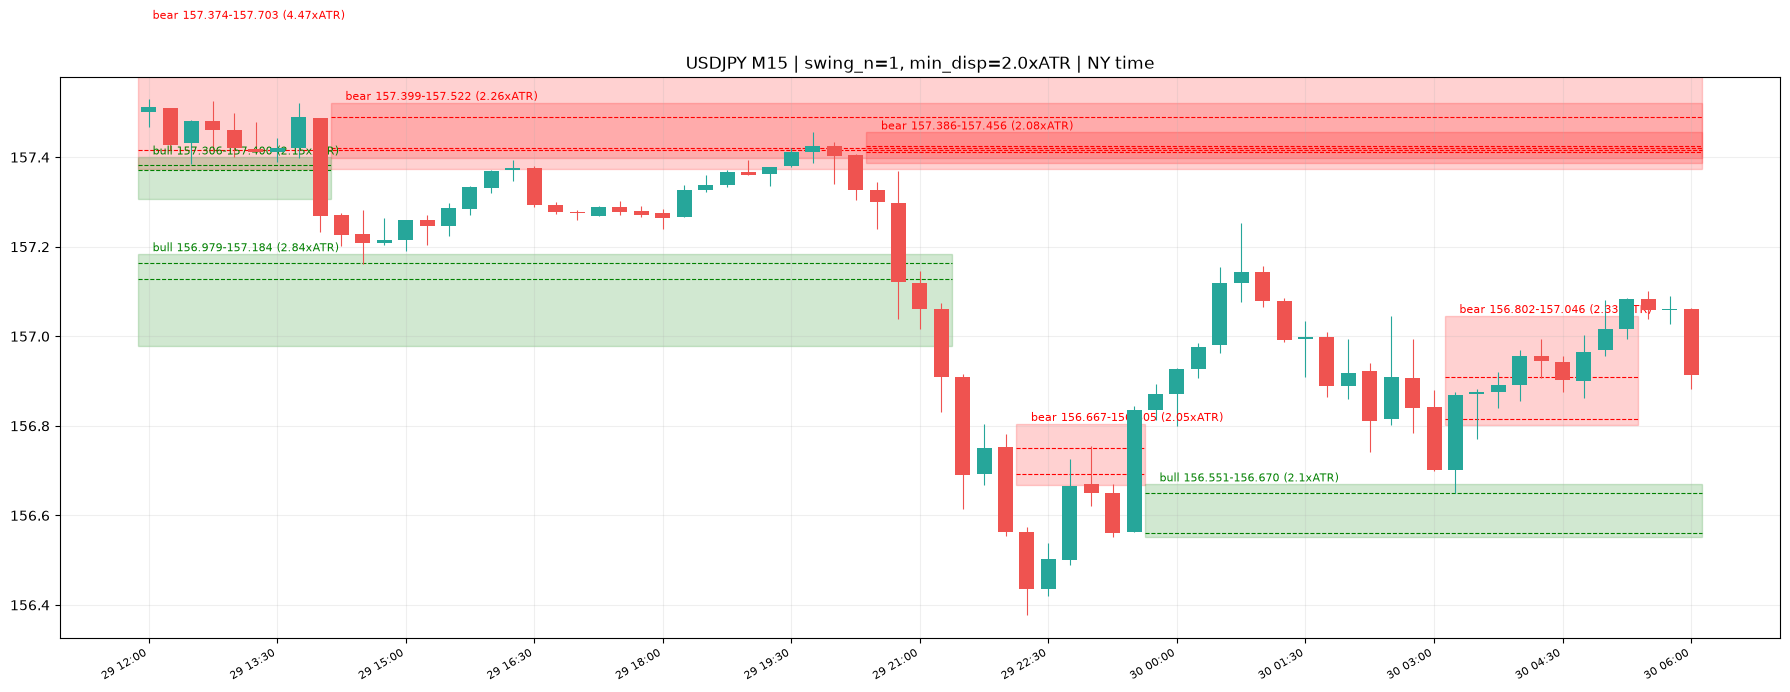

In [5]:
plot_zones(m15, z15, f"{SYMBOL} M15 | swing_n={SWING_N}, min_disp={MIN_DISP_ATR}xATR | NY time")

In [6]:
show_table(z15)

,direction,zone_candle_time,top,bottom,body_top,body_bottom,disp_atr,has_fvg,first_touch_time,first_touch_depth,touches,invalidated_time
11,bull,28 Sep 19:30,157.394,157.305,157.394,157.309,2.12,False,28 Sep 20:45,0.79,1,28 Sep 21:00
12,bear,28 Sep 20:30,157.495,157.444,157.450,157.447,3.07,True,28 Sep 21:30,2.18,1,28 Sep 21:30
13,bull,28 Sep 21:00,157.411,157.250,157.350,157.273,3.19,False,28 Sep 22:15,0.69,2,29 Sep 02:00
14,bull,28 Sep 23:15,157.290,157.203,157.288,157.266,2.10,True,29 Sep 02:00,0.75,3,29 Sep 06:45
15,bull,29 Sep 05:30,157.468,157.407,157.426,157.416,3.07,False,29 Sep 06:15,0.03,1,29 Sep 06:45
16,bear,29 Sep 05:45,157.703,157.374,157.701,157.417,4.47,True,29 Sep 09:00,0.06,4,NaN
17,bull,29 Sep 08:00,157.184,156.979,157.163,157.129,2.84,True,29 Sep 14:30,0.11,2,29 Sep 21:15
18,bull,29 Sep 10:30,157.400,157.306,157.382,157.372,2.15,False,29 Sep 12:30,0.16,2,29 Sep 14:00
19,bear,29 Sep 13:45,157.522,157.399,157.490,157.421,2.26,False,29 Sep 19:30,0.17,1,NaN
20,bear,29 Sep 19:45,157.456,157.386,157.426,157.411,2.08,False,NaN,NaN,0,NaN


## 6. H1 zones

Yahan tumhara **supply zone (~157.33-157.44)** dikhna chahiye.

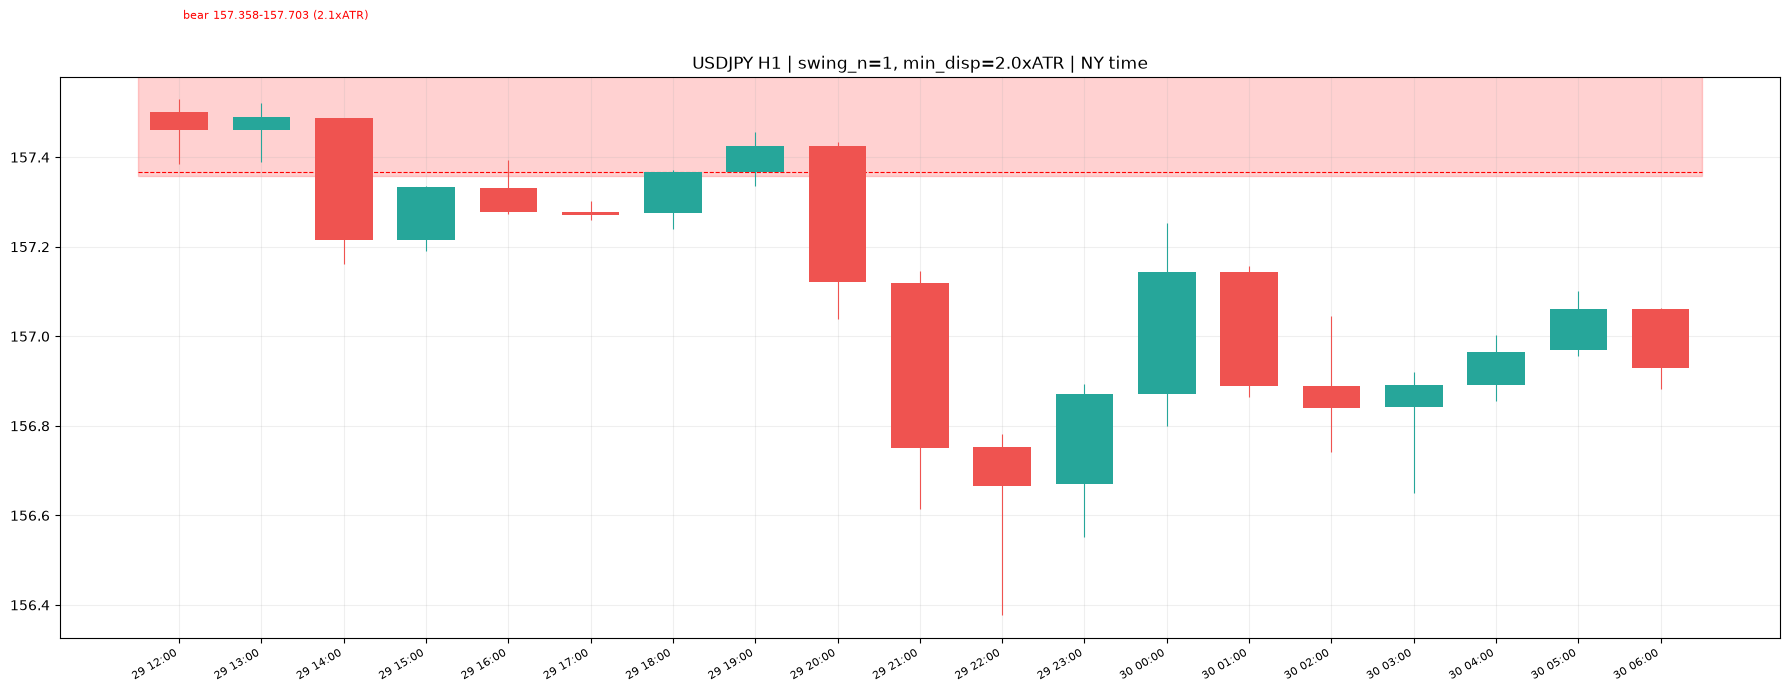

In [7]:
plot_zones(h1, zh1, f"{SYMBOL} H1 | swing_n={SWING_N}, min_disp={MIN_DISP_ATR}xATR | NY time")

In [8]:
show_table(zh1)

,direction,zone_candle_time,top,bottom,body_top,body_bottom,disp_atr,has_fvg,first_touch_time,first_touch_depth,touches,invalidated_time
2,bear,29 Sep 05:00,157.703,157.358,157.701,157.367,2.1,False,29 Sep 09:00,0.51,3,NaN


## 7. Tumhare notes

Chart dekh ke likho:
- Bot ne tumhare dono zones pakde? Box tumhare box se match karta hai?
- Aise zones jo bot ne pakde lekin tum **kabhi mark nahi karte**? Kyun nahi karte?
- Koi zone jo tum mark karte lekin bot ne **miss** kiya?

Settings (`SWING_N`, `MIN_DISP_ATR`) badal ke dobara chala ke bhi dekho.